# Workshop 05 – Machine Learning for IDS (Intrusion Detection System)

Sunnatbek Sobirov, 2461876, 6CS031

Dataset: KDD Cup 1999, `kddcup.data_10_percent_corrected` (10% training set, 494,021 connections). The original link on kdd.ics.uci.edu returns 403 Forbidden, so the file was taken from the scikit-learn mirror of the same dataset (https://archive.ics.uci.edu/dataset/130/kdd+cup+1999+data). The header row was added from `kddcup.names` and the last column was named `connection`.

In [1]:
import pandas as pd
import numpy as np

import matplotlib
%matplotlib inline
import matplotlib.pyplot as plt

import warnings
warnings.filterwarnings('ignore')

Reading and data transformation.

In [2]:
df = pd.read_csv('kddcup.data_10_percent_corrected.csv')

The code below will list out all the column names.

In [3]:
print(list(df))

['duration', 'protocol_type', 'service', 'flag', 'src_bytes', 'dst_bytes', 'land', 'wrong_fragment', 'urgent', 'hot', 'num_failed_logins', 'logged_in', 'num_compromised', 'root_shell', 'su_attempted', 'num_root', 'num_file_creations', 'num_shells', 'num_access_files', 'num_outbound_cmds', 'is_host_login', 'is_guest_login', 'count', 'srv_count', 'serror_rate', 'srv_serror_rate', 'rerror_rate', 'srv_rerror_rate', 'same_srv_rate', 'diff_srv_rate', 'srv_diff_host_rate', 'dst_host_count', 'dst_host_srv_count', 'dst_host_same_srv_rate', 'dst_host_diff_srv_rate', 'dst_host_same_src_port_rate', 'dst_host_srv_diff_host_rate', 'dst_host_serror_rate', 'dst_host_srv_serror_rate', 'dst_host_rerror_rate', 'dst_host_srv_rerror_rate', 'connection']


In [4]:
df['connection'].value_counts()

connection
smurf.              280790
neptune.            107201
normal.              97278
back.                 2203
satan.                1589
ipsweep.              1247
portsweep.            1040
warezclient.          1020
teardrop.              979
pod.                   264
nmap.                  231
guess_passwd.           53
buffer_overflow.        30
land.                   21
warezmaster.            20
imap.                   12
rootkit.                10
loadmodule.              9
ftp_write.               8
multihop.                7
phf.                     4
perl.                    3
spy.                     2
Name: count, dtype: int64

Let's store all the records in a dataframe **normal** where connection is 'normal'.

In [5]:
normal = df[df.connection == 'normal.']
normal.head()

,duration,protocol_type,service,flag,src_bytes,dst_bytes,land,wrong_fragment,urgent,hot,...,dst_host_srv_count,dst_host_same_srv_rate,dst_host_diff_srv_rate,dst_host_same_src_port_rate,dst_host_srv_diff_host_rate,dst_host_serror_rate,dst_host_srv_serror_rate,dst_host_rerror_rate,dst_host_srv_rerror_rate,connection
0,0,tcp,http,SF,181,5450,0,0,0,0,...,9,1.0,0.0,0.11,0.0,0.0,0.0,0.0,0.0,normal.
1,0,tcp,http,SF,239,486,0,0,0,0,...,19,1.0,0.0,0.05,0.0,0.0,0.0,0.0,0.0,normal.
2,0,tcp,http,SF,235,1337,0,0,0,0,...,29,1.0,0.0,0.03,0.0,0.0,0.0,0.0,0.0,normal.
3,0,tcp,http,SF,219,1337,0,0,0,0,...,39,1.0,0.0,0.03,0.0,0.0,0.0,0.0,0.0,normal.
4,0,tcp,http,SF,217,2032,0,0,0,0,...,49,1.0,0.0,0.02,0.0,0.0,0.0,0.0,0.0,normal.


In [6]:
print(normal.shape)
print(df.shape)

(97278, 42)
(494021, 42)


## Personalised dataset

Last 5 digits of my student number 2461876 → **61876**. A seed is set so the same sample is produced every time the notebook is run.

In [7]:
np.random.seed(61876)
rows = np.random.choice(df.index.values, 61876)
data = df.loc[rows]

In [8]:
data.to_csv('SunnatbekSobirov_61876.csv', index = False)

In [9]:
#data = pd.read_csv('SunnatbekSobirov_61876.csv')
data.shape

(61876, 42)

In [10]:
data.head()

,duration,protocol_type,service,flag,src_bytes,dst_bytes,land,wrong_fragment,urgent,hot,...,dst_host_srv_count,dst_host_same_srv_rate,dst_host_diff_srv_rate,dst_host_same_src_port_rate,dst_host_srv_diff_host_rate,dst_host_serror_rate,dst_host_srv_serror_rate,dst_host_rerror_rate,dst_host_srv_rerror_rate,connection
37591,0,tcp,http,SF,296,2337,0,0,0,0,...,255,1.00,0.00,0.01,0.03,0.0,0.01,0.0,0.0,normal.
427586,0,icmp,ecr_i,SF,520,0,0,0,0,0,...,255,1.00,0.00,1.00,0.00,0.0,0.00,0.0,0.0,smurf.
374252,0,tcp,private,S0,0,0,0,0,0,0,...,24,0.09,0.05,0.00,0.00,1.0,1.00,0.0,0.0,neptune.
480360,25,tcp,smtp,SF,1068,399,0,0,0,0,...,89,0.48,0.05,0.01,0.02,0.0,0.00,0.0,0.0,normal.
289431,0,icmp,ecr_i,SF,1032,0,0,0,0,0,...,255,1.00,0.00,1.00,0.00,0.0,0.00,0.0,0.0,smurf.


In [11]:
data['connection'].value_counts()

connection
smurf.              35173
neptune.            13412
normal.             12220
back.                 247
satan.                218
ipsweep.              158
portsweep.            128
warezclient.          120
teardrop.             117
pod.                   30
nmap.                  30
guess_passwd.           6
buffer_overflow.        4
land.                   4
warezmaster.            3
imap.                   2
ftp_write.              2
spy.                    1
rootkit.                1
Name: count, dtype: int64

**Observation – why are the counts different?**

The personalised dataset is not the full 10% file. It is a random sample of 61,876 rows out of its 494,021, which is roughly 12.5%. As a result, each class count is about 12.5% of the original. For example, smurf has 35,173 rows in my sample compared with 280,790 in the full file. The large classes keep nearly the same proportion, but the rare attacks are affected much more. Only 19 of the 23 connection types are present: `loadmodule`, `multihop`, `phf` and `perl` are missing completely, and `spy` and `rootkit` appear just once each. There is also a second effect. `np.random.choice` samples with replacement by default, so only 58,108 of the chosen indices are unique, and about 3,800 records were selected twice. Finally, the data is heavily imbalanced. The two DoS attacks, smurf and neptune, account for 78.5% of my sample, while normal traffic makes up only 19.7%.

In [12]:
data.head(10)

,duration,protocol_type,service,flag,src_bytes,dst_bytes,land,wrong_fragment,urgent,hot,...,dst_host_srv_count,dst_host_same_srv_rate,dst_host_diff_srv_rate,dst_host_same_src_port_rate,dst_host_srv_diff_host_rate,dst_host_serror_rate,dst_host_srv_serror_rate,dst_host_rerror_rate,dst_host_srv_rerror_rate,connection
37591,0,tcp,http,SF,296,2337,0,0,0,0,...,255,1.00,0.00,0.01,0.03,0.0,0.01,0.0,0.00,normal.
427586,0,icmp,ecr_i,SF,520,0,0,0,0,0,...,255,1.00,0.00,1.00,0.00,0.0,0.00,0.0,0.00,smurf.
374252,0,tcp,private,S0,0,0,0,0,0,0,...,24,0.09,0.05,0.00,0.00,1.0,1.00,0.0,0.00,neptune.
480360,25,tcp,smtp,SF,1068,399,0,0,0,0,...,89,0.48,0.05,0.01,0.02,0.0,0.00,0.0,0.00,normal.
289431,0,icmp,ecr_i,SF,1032,0,0,0,0,0,...,255,1.00,0.00,1.00,0.00,0.0,0.00,0.0,0.00,smurf.
126140,0,tcp,private,S0,0,0,0,0,0,0,...,16,0.06,0.07,0.00,0.00,1.0,1.00,0.0,0.00,neptune.
452663,0,tcp,http,SF,232,2013,0,0,0,0,...,240,0.94,0.01,0.00,0.00,0.0,0.00,0.0,0.00,normal.
147228,0,tcp,http,REJ,0,0,0,0,0,0,...,255,1.00,0.00,0.02,0.10,0.0,0.00,0.4,0.67,normal.
212170,0,icmp,ecr_i,SF,1032,0,0,0,0,0,...,255,1.00,0.00,1.00,0.00,0.0,0.00,0.0,0.00,smurf.
165110,0,icmp,ecr_i,SF,1032,0,0,0,0,0,...,255,1.00,0.00,1.00,0.00,0.0,0.00,0.0,0.00,smurf.


In [13]:
data.dtypes

duration                         int64
protocol_type                   object
service                         object
flag                            object
src_bytes                        int64
dst_bytes                        int64
land                             int64
wrong_fragment                   int64
urgent                           int64
hot                              int64
num_failed_logins                int64
logged_in                        int64
num_compromised                  int64
root_shell                       int64
su_attempted                     int64
num_root                         int64
num_file_creations               int64
num_shells                       int64
num_access_files                 int64
num_outbound_cmds                int64
is_host_login                    int64
is_guest_login                   int64
count                            int64
srv_count                        int64
serror_rate                    float64
srv_serror_rate          

There are different data types including int, float and object. Object is used to store string values, which have to be turned into numbers before sklearn can use them.

In [14]:
from sklearn.preprocessing import StandardScaler
from sklearn.preprocessing import LabelEncoder

In [15]:
obj_cols = data.select_dtypes(include=['object']).columns
print(obj_cols)

Index(['protocol_type', 'service', 'flag', 'connection'], dtype='object')


In [16]:
le = LabelEncoder()
for i in obj_cols:
    data[i] = le.fit_transform(data[i])

In [17]:
dict(zip(le.classes_, le.transform(le.classes_)))

{'back.': np.int64(0),
 'buffer_overflow.': np.int64(1),
 'ftp_write.': np.int64(2),
 'guess_passwd.': np.int64(3),
 'imap.': np.int64(4),
 'ipsweep.': np.int64(5),
 'land.': np.int64(6),
 'neptune.': np.int64(7),
 'nmap.': np.int64(8),
 'normal.': np.int64(9),
 'pod.': np.int64(10),
 'portsweep.': np.int64(11),
 'rootkit.': np.int64(12),
 'satan.': np.int64(13),
 'smurf.': np.int64(14),
 'spy.': np.int64(15),
 'teardrop.': np.int64(16),
 'warezclient.': np.int64(17),
 'warezmaster.': np.int64(18)}

In [18]:
data.dtypes

duration                         int64
protocol_type                    int64
service                          int64
flag                             int64
src_bytes                        int64
dst_bytes                        int64
land                             int64
wrong_fragment                   int64
urgent                           int64
hot                              int64
num_failed_logins                int64
logged_in                        int64
num_compromised                  int64
root_shell                       int64
su_attempted                     int64
num_root                         int64
num_file_creations               int64
num_shells                       int64
num_access_files                 int64
num_outbound_cmds                int64
is_host_login                    int64
is_guest_login                   int64
count                            int64
srv_count                        int64
serror_rate                    float64
srv_serror_rate          

**Q. What difference can you observe?**

After encoding, the four text (`object`) columns `protocol_type`, `service`, `flag` and `connection` have become `int64`. The rest of the columns are unchanged. LabelEncoder assigned each category a number in alphabetical order. In `connection`, for instance, back. = 0, normal. = 9 and smurf. = 14. In `protocol_type`, icmp = 0, tcp = 1 and udp = 2.

This creates a problem, because the numbers imply an order that does not really exist: udp is not "bigger" than tcp. Tree-based models such as Random Forest are not affected by this. For distance-based models like KNN or SVM, however, one-hot encoding would be the better choice. Another issue is that the same `le` object was reused for every column. After the loop, it only remembers the labels of `connection`, so the other columns cannot be decoded back.

In [19]:
data.head()

,duration,protocol_type,service,flag,src_bytes,dst_bytes,land,wrong_fragment,urgent,hot,...,dst_host_srv_count,dst_host_same_srv_rate,dst_host_diff_srv_rate,dst_host_same_src_port_rate,dst_host_srv_diff_host_rate,dst_host_serror_rate,dst_host_srv_serror_rate,dst_host_rerror_rate,dst_host_srv_rerror_rate,connection
37591,0,1,22,8,296,2337,0,0,0,0,...,255,1.00,0.00,0.01,0.03,0.0,0.01,0.0,0.0,9
427586,0,0,14,8,520,0,0,0,0,0,...,255,1.00,0.00,1.00,0.00,0.0,0.00,0.0,0.0,14
374252,0,1,45,4,0,0,0,0,0,0,...,24,0.09,0.05,0.00,0.00,1.0,1.00,0.0,0.0,7
480360,25,1,49,8,1068,399,0,0,0,0,...,89,0.48,0.05,0.01,0.02,0.0,0.00,0.0,0.0,9
289431,0,0,14,8,1032,0,0,0,0,0,...,255,1.00,0.00,1.00,0.00,0.0,0.00,0.0,0.0,14


In [20]:
columns = list(data)
columns = columns[:-1]

Scaling the input data to have zero mean and unit variance.

In [21]:
scaler = StandardScaler()

In [22]:
sc_data = scaler.fit_transform(data[columns])

In [23]:
print(sc_data)

[[-0.06440342  0.92654963 -0.10198484 ... -0.4349443  -0.25373555
  -0.25155677]
 [-0.06440342 -0.8113383  -0.69494347 ... -0.46126635 -0.25373555
  -0.25155677]
 [-0.06440342  0.92654963  1.60277122 ...  2.17093885 -0.25373555
  -0.25155677]
 ...
 [-0.06440342 -0.8113383  -0.69494347 ... -0.46126635 -0.25373555
  -0.25155677]
 [-0.06440342  0.92654963  1.23217207 ... -0.46126635  4.06053293
   4.05737503]
 [-0.06440342 -0.8113383  -0.69494347 ... -0.46126635 -0.25373555
  -0.25155677]]


In [24]:
transformed_data = pd.DataFrame(sc_data, columns = columns)

In [25]:
transformed_data.head()

,duration,protocol_type,service,flag,src_bytes,dst_bytes,land,wrong_fragment,urgent,hot,...,dst_host_count,dst_host_srv_count,dst_host_same_srv_rate,dst_host_diff_srv_rate,dst_host_same_src_port_rate,dst_host_srv_diff_host_rate,dst_host_serror_rate,dst_host_srv_serror_rate,dst_host_rerror_rate,dst_host_srv_rerror_rate
0,-0.064403,0.926550,-0.101985,0.513468,-0.023131,0.049377,-0.00804,-0.046346,0.0,-0.042116,...,-1.962639,0.626385,0.599884,-0.283544,-1.229192,0.552081,-0.462682,-0.434944,-0.253736,-0.251557
1,-0.064403,-0.811338,-0.694943,0.513468,-0.019699,-0.026879,-0.00804,-0.046346,0.0,-0.042116,...,0.349729,0.626385,0.599884,-0.283544,0.827602,-0.158123,-0.462682,-0.461266,-0.253736,-0.251557
2,-0.064403,0.926550,1.602771,-1.259833,-0.027666,-0.026879,-0.00804,-0.046346,0.0,-0.042116,...,0.349729,-1.551782,-1.614901,0.172486,-1.249968,-0.158123,2.171999,2.170939,-0.253736,-0.251557
3,-0.028918,0.926550,1.899251,0.513468,-0.011302,-0.013860,-0.00804,-0.046346,0.0,-0.042116,...,-2.116797,-0.938878,-0.665707,0.172486,-1.229192,0.315347,-0.462682,-0.461266,-0.253736,-0.251557
4,-0.064403,-0.811338,-0.694943,0.513468,-0.011854,-0.026879,-0.00804,-0.046346,0.0,-0.042116,...,0.349729,0.626385,0.599884,-0.283544,0.827602,-0.158123,-0.462682,-0.461266,-0.253736,-0.251557


In [26]:
full = transformed_data.copy()
full['connection'] = data['connection'].values
full.head()

,duration,protocol_type,service,flag,src_bytes,dst_bytes,land,wrong_fragment,urgent,hot,...,dst_host_srv_count,dst_host_same_srv_rate,dst_host_diff_srv_rate,dst_host_same_src_port_rate,dst_host_srv_diff_host_rate,dst_host_serror_rate,dst_host_srv_serror_rate,dst_host_rerror_rate,dst_host_srv_rerror_rate,connection
0,-0.064403,0.926550,-0.101985,0.513468,-0.023131,0.049377,-0.00804,-0.046346,0.0,-0.042116,...,0.626385,0.599884,-0.283544,-1.229192,0.552081,-0.462682,-0.434944,-0.253736,-0.251557,9
1,-0.064403,-0.811338,-0.694943,0.513468,-0.019699,-0.026879,-0.00804,-0.046346,0.0,-0.042116,...,0.626385,0.599884,-0.283544,0.827602,-0.158123,-0.462682,-0.461266,-0.253736,-0.251557,14
2,-0.064403,0.926550,1.602771,-1.259833,-0.027666,-0.026879,-0.00804,-0.046346,0.0,-0.042116,...,-1.551782,-1.614901,0.172486,-1.249968,-0.158123,2.171999,2.170939,-0.253736,-0.251557,7
3,-0.028918,0.926550,1.899251,0.513468,-0.011302,-0.013860,-0.00804,-0.046346,0.0,-0.042116,...,-0.938878,-0.665707,0.172486,-1.229192,0.315347,-0.462682,-0.461266,-0.253736,-0.251557,9
4,-0.064403,-0.811338,-0.694943,0.513468,-0.011854,-0.026879,-0.00804,-0.046346,0.0,-0.042116,...,0.626385,0.599884,-0.283544,0.827602,-0.158123,-0.462682,-0.461266,-0.253736,-0.251557,14


In [27]:
target = data['connection'].values
target[:10]

array([ 9, 14,  7,  9, 14,  7,  9,  9, 14, 14])

In [28]:
from sklearn.model_selection import train_test_split
from sklearn import metrics
from sklearn.metrics import confusion_matrix
from sklearn.metrics import classification_report

In [29]:
x_train, x_test, y_train, y_test = train_test_split(transformed_data, target, test_size= .33,
                                                    random_state = 8)

print(x_train.shape, x_test.shape)

(41456, 41) (20420, 41)


In [30]:
from sklearn.ensemble import RandomForestClassifier

In [31]:
rfc = RandomForestClassifier(random_state = 8)
rfc_model = rfc.fit(x_train, y_train)
rfc.score(x_test, y_test)

0.9995592556317336

In [32]:
feature_importance = pd.DataFrame(rfc.feature_importances_, index = x_train.columns,
                                  columns=['importance']).sort_values('importance', ascending=False)
feature_importance

,importance
protocol_type,1.462452e-01
count,1.459241e-01
srv_count,1.158700e-01
src_bytes,8.239676e-02
service,7.778521e-02
diff_srv_rate,6.503776e-02
dst_host_same_src_port_rate,6.381807e-02
same_srv_rate,5.592341e-02
dst_host_same_srv_rate,5.209649e-02
flag,4.237728e-02


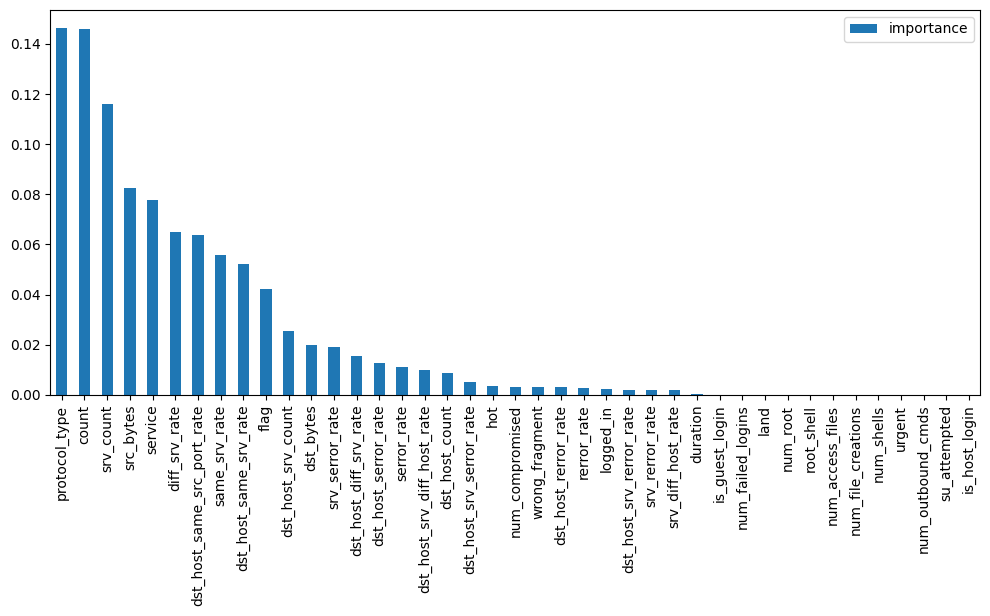

In [33]:
plt.rcParams['figure.figsize'] = (12, 5)
feature_importance.plot.bar();

In [34]:
print(rfc_model)

pred = rfc_model.predict(x_test)
matrix_rfc = confusion_matrix(y_test, pred)
print(matrix_rfc)
print(classification_report(y_test, pred, labels=np.unique(y_test), target_names=le.inverse_transform(np.unique(y_test)), zero_division=0))

RandomForestClassifier(random_state=8)


[[   94     0     0     0     0     0     0     0     0     0     0     0
      0     0     0     0     0     0]
 [    0     0     0     0     0     0     0     0     0     1     0     0
      0     0     0     0     0     0]
 [    0     0     1     0     0     0     0     0     0     0     0     0
      0     0     0     0     0     0]
 [    0     0     0     1     0     0     0     0     0     0     0     0
      0     0     0     0     0     0]
 [    0     0     0     0     0     0     0     0     0     1     0     0
      0     0     0     0     0     0]
 [    0     0     0     0     0    49     0     0     0     1     0     0
      0     0     0     0     0     0]
 [    0     0     0     0     0     0     1     0     0     0     0     0
      0     0     0     0     0     0]
 [    0     0     0     0     0     0     0  4412     0     0     0     0
      0     0     0     0     0     0]
 [    0     0     0     0     0     0     0     0     7     1     0     0
      0     0     0   

**Observation – Random Forest results**

On the 20,420 test connections, Random Forest achieved 99.96% accuracy and a weighted average F1 of 1.00. At first sight this looks perfect. The macro average F1, however, is only 0.83. The reason is that classes with just one test sample (`buffer_overflow`, `imap`, `spy`) were all predicted as `normal.`.

For an IDS, this is the worst type of mistake. The huge DoS classes are easy to detect, but the rare R2L and U2R attacks are missed entirely, which means false negatives.

The score is also too optimistic, for two reasons:

1. The KDD data contains a lot of duplicates. My sample has only 22,093 unique rows out of 61,876, and the full 10% file has 348,435 duplicate rows. This means identical records end up in both the training set and the test set.
2. The scaler was fitted on the whole dataset before it was split.

For the assessment, I would make four changes:

- remove the duplicates;
- use a stratified split;
- group the attacks into the 5 categories (normal, DoS, Probe, R2L, U2R);
- evaluate the models by macro F1 and recall instead of accuracy.

Feature importance using RFE (Recursive Feature Elimination).

In [35]:
from sklearn.feature_selection import RFE
import itertools

In [36]:
rfe = RFE(rfc, n_features_to_select=15)
rfe = rfe.fit(x_train, y_train)

print(rfe.get_support())

[False  True  True  True  True  True False False False False False False
 False False False False False False False False False False  True  True
 False False False False  True  True False False  True  True  True  True
  True  True False False False]


In [37]:
feature_map = [(i, v) for i, v in itertools.zip_longest(rfe.get_support(), x_train.columns)]
selected_features = [v for i, v in feature_map if i==True]

selected_features

['protocol_type',
 'service',
 'flag',
 'src_bytes',
 'dst_bytes',
 'count',
 'srv_count',
 'same_srv_rate',
 'diff_srv_rate',
 'dst_host_srv_count',
 'dst_host_same_srv_rate',
 'dst_host_diff_srv_rate',
 'dst_host_same_src_port_rate',
 'dst_host_srv_diff_host_rate',
 'dst_host_serror_rate']

In [38]:
rfc15 = RandomForestClassifier(random_state = 8).fit(x_train[selected_features], y_train)
print('41 features:', rfc.score(x_test, y_test))
print('15 RFE features:', rfc15.score(x_test[selected_features], y_test))

41 features: 0.9995592556317336


15 RFE features: 0.9993143976493634


**Observation – feature importance and RFE**

The five most important features are `protocol_type`, `count`, `srv_count`, `src_bytes` and `service`. This fits what smurf and neptune actually do. Both are flood attacks, so they open many connections to the same host and service within two seconds, which shows up in `count` and `srv_count`. Smurf also uses ICMP echo replies (`ecr_i`) with a fixed packet size, so `src_bytes` is always 520 or 1032.

At the other end, several features have zero or almost zero importance: `urgent`, `num_outbound_cmds`, `su_attempted` and `is_host_login`. `num_outbound_cmds` is always 0, so it carries no information at all.

RFE selected 15 features, and 14 of them match the workshop example. The one difference is that `dst_host_serror_rate` replaced `num_compromised`, which is expected because my personalised sample is different. A Random Forest trained on just these 15 features scored 99.93%, compared with 99.96% using all 41. In other words, almost two thirds of the features can be dropped with hardly any loss in accuracy, and the model becomes faster and simpler as a result.